In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("india_regional_market_v2.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (400, 11)


,RegionID,City,State,Latitude,Longitude,PopulationSegment,MonthlySearchDemand,ExistingCompetitors,MedianAnnualIncomeINR,LeadConversionRate,EstimatedAcquisitionCostINR
0,REG-0001,Delhi,Delhi,28.65506,77.14308,Student,1071,9,812870,0.1116,618
1,REG-0002,Hyderabad,Telangana,17.45908,78.36344,Student,654,15,938393,0.1228,748
2,REG-0003,Delhi,Delhi,28.56055,77.13678,Professional,574,10,445873,0.1191,634
3,REG-0004,Kolkata,West Bengal,22.70194,88.38826,Professional,389,4,802466,0.0308,330
4,REG-0005,Pune,Maharashtra,18.58053,73.76657,Student,538,11,370930,0.0974,150


In [4]:
# Dataset information
print("DATASET INFORMATION")
print("-------------------")
df.info()

print("\nMISSING VALUES")
print("--------------")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print("--------------")
print("Duplicate rows:", df.duplicated().sum())

print("\nDUPLICATE REGION IDs")
print("--------------------")
print("Duplicate RegionIDs:", df["RegionID"].duplicated().sum())

print("\nNUMERICAL SUMMARY")
print("-----------------")
display(df.describe())

print("\nCATEGORICAL SUMMARY")
print("-------------------")
display(df.describe(include="object"))

DATASET INFORMATION
-------------------
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   RegionID                     400 non-null    str    
 1   City                         400 non-null    str    
 2   State                        400 non-null    str    
 3   Latitude                     400 non-null    float64
 4   Longitude                    400 non-null    float64
 5   PopulationSegment            400 non-null    str    
 6   MonthlySearchDemand          400 non-null    int64  
 7   ExistingCompetitors          400 non-null    int64  
 8   MedianAnnualIncomeINR        400 non-null    int64  
 9   LeadConversionRate           400 non-null    float64
 10  EstimatedAcquisitionCostINR  400 non-null    int64  
dtypes: float64(3), int64(4), str(4)
memory usage: 34.5 KB

MISSING VALUES
--------------
RegionID              

,Latitude,Longitude,MonthlySearchDemand,ExistingCompetitors,MedianAnnualIncomeINR,LeadConversionRate,EstimatedAcquisitionCostINR
count,400.000000,400.000000,400.000000,400.000000,4.000000e+02,400.000000,400.0000
mean,19.514412,77.189472,1061.547500,7.770000,6.743837e+05,0.079196,461.5500
std,6.024531,4.090443,506.055048,4.430143,2.259640e+05,0.036676,217.9737
min,9.755410,72.397790,189.000000,1.000000,2.850710e+05,0.018200,91.0000
25%,13.136885,73.839768,630.500000,4.000000,4.727375e+05,0.047100,268.0000
50%,18.668290,77.082815,1055.000000,8.000000,6.912940e+05,0.079700,451.0000
75%,23.141262,78.489573,1484.000000,12.000000,8.781878e+05,0.111625,645.7500
max,28.767430,88.534650,1899.000000,15.000000,1.047851e+06,0.139700,850.0000



CATEGORICAL SUMMARY
-------------------


C:\Users\SHREE VATHY\AppData\Local\Temp\ipykernel_17244\1347947912.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,RegionID,City,State,PopulationSegment
count,400,400,400,400
unique,400,10,9,3
top,REG-0001,Delhi,Maharashtra,Professional
freq,1,56,69,145


In [5]:
# Geographic coordinate validation
invalid_latitude = df[
    (df["Latitude"] < -90) | (df["Latitude"] > 90)
]

invalid_longitude = df[
    (df["Longitude"] < -180) | (df["Longitude"] > 180)
]

# India approximate geographic boundary check
outside_india = df[
    (df["Latitude"] < 6) | (df["Latitude"] > 38) |
    (df["Longitude"] < 68) | (df["Longitude"] > 98)
]

# Numeric validation
invalid_conversion = df[
    (df["LeadConversionRate"] < 0) |
    (df["LeadConversionRate"] > 1)
]

negative_values = df[
    (df["MonthlySearchDemand"] < 0) |
    (df["ExistingCompetitors"] < 0) |
    (df["MedianAnnualIncomeINR"] < 0) |
    (df["EstimatedAcquisitionCostINR"] < 0)
]

print("GEOGRAPHIC VALIDATION")
print("Invalid latitude:", len(invalid_latitude))
print("Invalid longitude:", len(invalid_longitude))
print("Outside approximate India bounds:", len(outside_india))

print("\nNUMERIC VALIDATION")
print("Invalid conversion rates:", len(invalid_conversion))
print("Negative numeric records:", len(negative_values))

print("\nCITY AND STATE COUNTS")
print("Cities:", df["City"].nunique())
print("States:", df["State"].nunique())
print("Population segments:", df["PopulationSegment"].unique())

GEOGRAPHIC VALIDATION
Invalid latitude: 0
Invalid longitude: 0
Outside approximate India bounds: 0

NUMERIC VALIDATION
Invalid conversion rates: 0
Negative numeric records: 0

CITY AND STATE COUNTS
Cities: 10
States: 9
Population segments: <StringArray>
['Student', 'Professional', 'Early Career']
Length: 3, dtype: str


In [6]:
# Create a working copy
geo_df = df.copy()

# Standardize text columns
text_columns = ["RegionID", "City", "State", "PopulationSegment"]

for col in text_columns:
    geo_df[col] = geo_df[col].str.strip()

# Standardize text casing
geo_df["City"] = geo_df["City"].str.title()
geo_df["State"] = geo_df["State"].str.title()
geo_df["PopulationSegment"] = geo_df["PopulationSegment"].str.title()

# Remove exact duplicate records if any
geo_df = geo_df.drop_duplicates()

# Check final data quality
print("CLEANING COMPLETED")
print("------------------")
print("Final Shape:", geo_df.shape)
print("Missing Values:", geo_df.isnull().sum().sum())
print("Duplicate Rows:", geo_df.duplicated().sum())
print("Duplicate RegionIDs:", geo_df["RegionID"].duplicated().sum())

print("\nCleaned Dataset Preview:")
display(geo_df.head())

CLEANING COMPLETED
------------------
Final Shape: (400, 11)
Missing Values: 0
Duplicate Rows: 0
Duplicate RegionIDs: 0

Cleaned Dataset Preview:


,RegionID,City,State,Latitude,Longitude,PopulationSegment,MonthlySearchDemand,ExistingCompetitors,MedianAnnualIncomeINR,LeadConversionRate,EstimatedAcquisitionCostINR
0,REG-0001,Delhi,Delhi,28.65506,77.14308,Student,1071,9,812870,0.1116,618
1,REG-0002,Hyderabad,Telangana,17.45908,78.36344,Student,654,15,938393,0.1228,748
2,REG-0003,Delhi,Delhi,28.56055,77.13678,Professional,574,10,445873,0.1191,634
3,REG-0004,Kolkata,West Bengal,22.70194,88.38826,Professional,389,4,802466,0.0308,330
4,REG-0005,Pune,Maharashtra,18.58053,73.76657,Student,538,11,370930,0.0974,150


In [7]:
# State-wise market aggregation

state_analysis = geo_df.groupby("State").agg(
    Total_Regions=("RegionID", "count"),
    Total_Cities=("City", "nunique"),
    Total_Search_Demand=("MonthlySearchDemand", "sum"),
    Average_Search_Demand=("MonthlySearchDemand", "mean"),
    Average_Competitors=("ExistingCompetitors", "mean"),
    Average_Income=("MedianAnnualIncomeINR", "mean"),
    Average_Conversion_Rate=("LeadConversionRate", "mean"),
    Average_Acquisition_Cost=("EstimatedAcquisitionCostINR", "mean")
).round(2)

state_analysis = state_analysis.sort_values(
    by="Total_Search_Demand",
    ascending=False
)

display(state_analysis)

,Total_Regions,Total_Cities,Total_Search_Demand,Average_Search_Demand,Average_Competitors,Average_Income,Average_Conversion_Rate,Average_Acquisition_Cost
State,,,,,,,,
Maharashtra,69,2,75849,1099.26,7.62,664141.33,0.08,469.97
Tamil Nadu,47,1,53771,1144.06,7.94,678182.09,0.08,411.68
Delhi,56,1,53007,946.55,8.02,701424.14,0.07,486.23
Gujarat,50,1,52110,1042.20,8.38,710723.80,0.08,487.00
Telangana,42,1,48103,1145.31,7.19,665610.38,0.08,438.57
Kerala,39,1,39015,1000.38,6.79,660594.08,0.08,520.38
Rajasthan,33,1,34849,1056.03,7.67,668222.45,0.08,446.85
West Bengal,32,1,34126,1066.44,8.56,649083.97,0.07,392.50
Karnataka,32,1,33789,1055.91,7.72,646762.56,0.09,476.34


In [8]:
from sklearn.preprocessing import MinMaxScaler

# Create regional opportunity dataset
region_opportunity = geo_df.copy()

scaler = MinMaxScaler()

# Normalize market indicators
region_opportunity["Demand_Score"] = scaler.fit_transform(
    region_opportunity[["MonthlySearchDemand"]]
)

region_opportunity["Competition_Score"] = 1 - scaler.fit_transform(
    region_opportunity[["ExistingCompetitors"]]
)

region_opportunity["Conversion_Score"] = scaler.fit_transform(
    region_opportunity[["LeadConversionRate"]]
)

region_opportunity["Income_Score"] = scaler.fit_transform(
    region_opportunity[["MedianAnnualIncomeINR"]]
)

region_opportunity["Cost_Score"] = 1 - scaler.fit_transform(
    region_opportunity[["EstimatedAcquisitionCostINR"]]
)

# Weighted opportunity score
region_opportunity["Opportunity_Score"] = (
    region_opportunity["Demand_Score"] * 0.40 +
    region_opportunity["Competition_Score"] * 0.25 +
    region_opportunity["Conversion_Score"] * 0.20 +
    region_opportunity["Income_Score"] * 0.10 +
    region_opportunity["Cost_Score"] * 0.05
) * 100

# Top 3 high-potential regions
top_3_regions = region_opportunity.sort_values(
    "Opportunity_Score", ascending=False
).head(3)

display(top_3_regions[[
    "RegionID", "City", "State",
    "MonthlySearchDemand", "ExistingCompetitors",
    "LeadConversionRate", "EstimatedAcquisitionCostINR",
    "Opportunity_Score"
]].round(2))

,RegionID,City,State,MonthlySearchDemand,ExistingCompetitors,LeadConversionRate,EstimatedAcquisitionCostINR,Opportunity_Score
205,REG-0206,Kochi,Kerala,1787,1,0.13,407,90.88
352,REG-0353,Kolkata,West Bengal,1799,1,0.14,727,89.47
372,REG-0373,Chennai,Tamil Nadu,1831,5,0.12,228,86.30


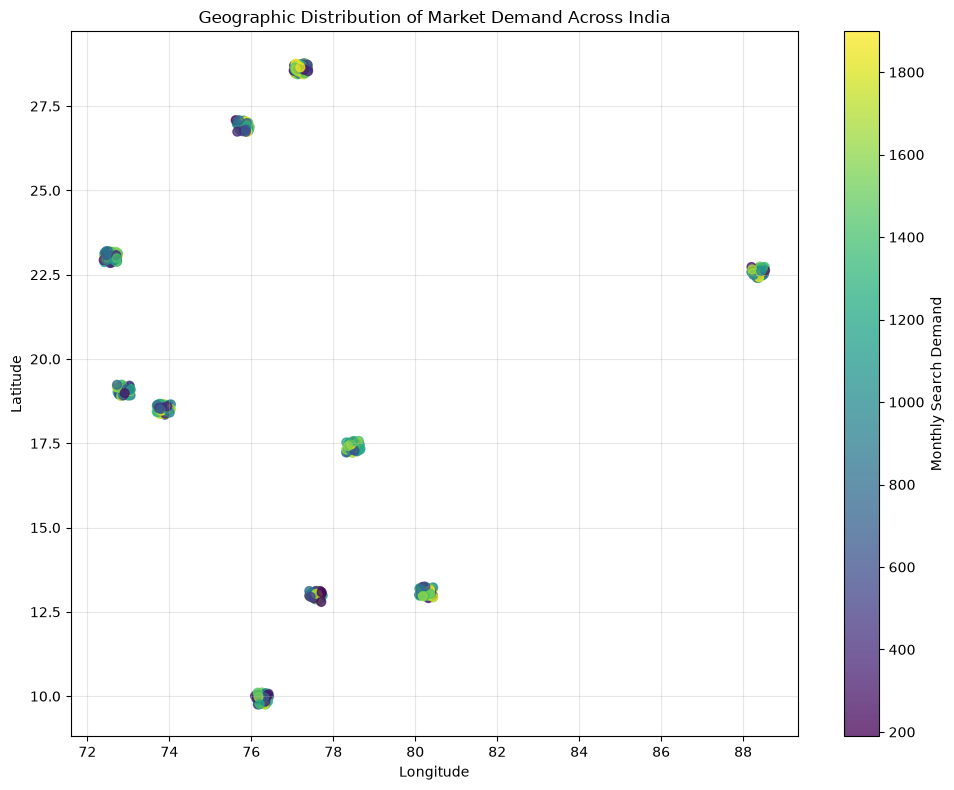

In [9]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    geo_df["Longitude"],
    geo_df["Latitude"],
    c=geo_df["MonthlySearchDemand"],
    cmap="viridis",
    s=40,
    alpha=0.75
)

plt.colorbar(scatter, label="Monthly Search Demand")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Market Demand Across India")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
!pip install folium


   ------------- -------------------------- 1/3 [branca]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   ---------------------------------------- 3/3 [folium]




[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\SHREE VATHY\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [16]:
state_analysis.to_csv(
    "output/state_market_analysis.csv"
)

top_3_regions[[
    "RegionID",
    "City",
    "State",
    "MonthlySearchDemand",
    "ExistingCompetitors",
    "LeadConversionRate",
    "EstimatedAcquisitionCostINR",
    "Opportunity_Score"
]].round(2).to_csv(
    "output/top_3_opportunity_regions.csv",
    index=False
)

region_opportunity.to_csv(
    "output/regional_opportunity_scores.csv",
    index=False
)

print("All analysis CSV files exported successfully!")

All analysis CSV files exported successfully!


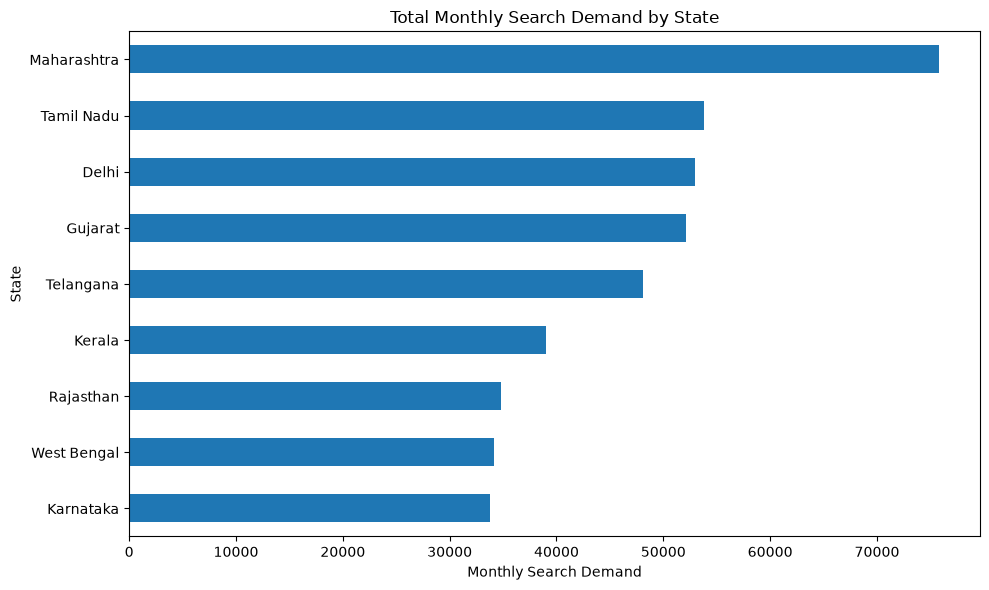

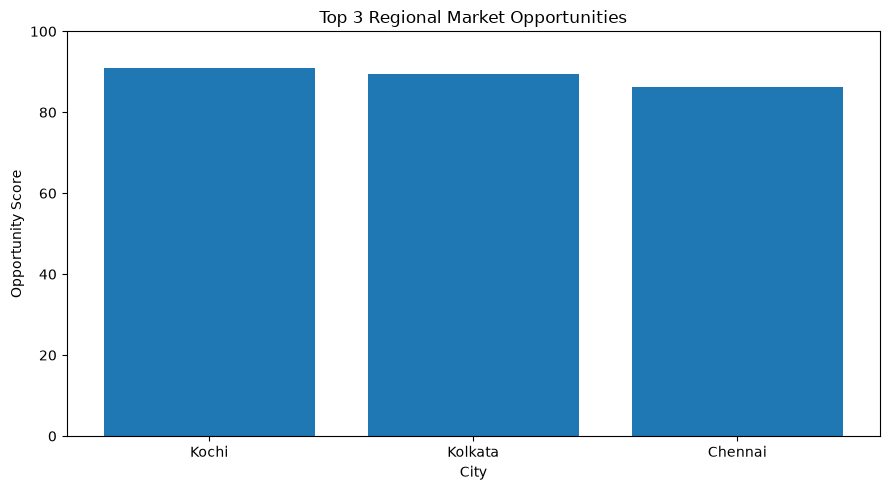

Both charts saved successfully!


In [17]:
os.makedirs("output/charts", exist_ok=True)

# Chart 1: State-wise search demand
plt.figure(figsize=(10, 6))

state_analysis["Total_Search_Demand"].sort_values().plot(
    kind="barh"
)

plt.title("Total Monthly Search Demand by State")
plt.xlabel("Monthly Search Demand")
plt.ylabel("State")
plt.tight_layout()

plt.savefig("output/charts/state_search_demand.png", dpi=300)
plt.show()


# Chart 2: Top 3 opportunity regions
plt.figure(figsize=(9, 5))

plt.bar(
    top_3_regions["City"],
    top_3_regions["Opportunity_Score"]
)

plt.title("Top 3 Regional Market Opportunities")
plt.xlabel("City")
plt.ylabel("Opportunity Score")
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig("output/charts/top_3_opportunity_regions.png", dpi=300)
plt.show()

print("Both charts saved successfully!")

In [18]:
!pip install reportlab


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\SHREE VATHY\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [19]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, Table, TableStyle, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch
import os

os.makedirs("output", exist_ok=True)

pdf_path = "output/geospatial_analysis_report.pdf"

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()
story = []

title_style = ParagraphStyle(
    "ReportTitle",
    parent=styles["Title"],
    textColor=colors.HexColor("#174A7E"),
    fontSize=20,
    spaceAfter=15
)

heading_style = ParagraphStyle(
    "SectionHeading",
    parent=styles["Heading2"],
    textColor=colors.HexColor("#174A7E"),
    spaceBefore=12,
    spaceAfter=8
)

# Title
story.append(Paragraph(
    "GEOSPATIAL DATA ANALYSIS",
    title_style
))
story.append(Paragraph(
    "Regional Market Opportunity & Expansion Analysis",
    styles["Heading2"]
))
story.append(Paragraph(
    "Prepared by: S. SHREE VATHY",
    styles["Normal"]
))
story.append(Spacer(1, 15))

# 1. Overview
story.append(Paragraph("1. Project Overview", heading_style))
story.append(Paragraph(
    "This project analyzes synthetic city-level geographic market "
    "data across India to identify promising regional expansion "
    "opportunities using search demand, competition, lead conversion, "
    "income and estimated acquisition cost.",
    styles["BodyText"]
))

# 2. Dataset
story.append(Paragraph("2. Dataset & Quality Validation", heading_style))
validation_data = [
    ["Metric", "Result"],
    ["Dataset records", str(len(geo_df))],
    ["Columns", str(len(geo_df.columns))],
    ["Missing values", str(geo_df.isnull().sum().sum())],
    ["Duplicate rows", str(geo_df.duplicated().sum())],
    ["Unique Region IDs", str(geo_df["RegionID"].nunique())],
    ["Unique cities", str(geo_df["City"].nunique())],
    ["Unique states", str(geo_df["State"].nunique())]
]

table = Table(validation_data, colWidths=[220, 180])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#174A7E")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7)
]))
story.append(table)

# 3. Methodology
story.append(Paragraph("3. Methodology", heading_style))
story.append(Paragraph(
    "The dataset was checked for missing values, duplicates, valid "
    "coordinates and invalid numerical values. Text fields were "
    "standardized. State-level metrics were aggregated. A weighted "
    "opportunity score was calculated using normalized demand (40%), "
    "lower competition (25%), conversion rate (20%), income (10%) "
    "and lower acquisition cost (5%).",
    styles["BodyText"]
))

# 4. State analysis chart
story.append(Paragraph("4. State-wise Market Demand", heading_style))
story.append(Image(
    "output/charts/state_search_demand.png",
    width=6.5 * inch,
    height=3.8 * inch
))

# 5. Top regions
story.append(Paragraph("5. Top 3 Opportunity Regions", heading_style))

top_data = [[
    "Region ID", "City", "State", "Demand", "Score"
]]

for _, row in top_3_regions.iterrows():
    top_data.append([
        str(row["RegionID"]),
        str(row["City"]),
        str(row["State"]),
        str(row["MonthlySearchDemand"]),
        f'{row["Opportunity_Score"]:.2f}'
    ])

top_table = Table(
    top_data,
    colWidths=[85, 75, 95, 70, 65]
)
top_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#174A7E")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 6)
]))
story.append(top_table)

story.append(Spacer(1, 10))
story.append(Image(
    "output/charts/top_3_opportunity_regions.png",
    width=6.2 * inch,
    height=3.5 * inch
))

# 6. Findings
story.append(Paragraph("6. Key Findings", heading_style))
for item in [
    "Kochi, Kerala achieved the highest opportunity score of 90.88.",
    "Kolkata, West Bengal ranked second with a score of 89.47.",
    "Chennai, Tamil Nadu ranked third with a score of 86.30.",
    "The selected regions combine strong search demand with relatively low competition."
]:
    story.append(Paragraph("• " + item, styles["BodyText"]))
    story.append(Spacer(1, 5))

# 7. Recommendations
story.append(Paragraph("7. Business Recommendations", heading_style))
story.append(Paragraph(
    "Prioritize further market research in Kochi, Kolkata and Chennai. "
    "Validate customer demand through local surveys and pilot campaigns. "
    "Compare actual acquisition costs and conversion performance before "
    "committing expansion budgets.",
    styles["BodyText"]
))

# 8. Limitations
story.append(Paragraph("8. Dataset Limitations", heading_style))
story.append(Paragraph(
    "The dataset contains synthetic coordinates and market indicators. "
    "It does not provide actual sales revenue, postal codes, population "
    "counts or verified user density. Monthly search demand is used as "
    "a demand indicator, not as actual customer count. Region record "
    "counts indicate dataset coverage, not population density. The "
    "opportunity score is a custom weighted ranking and should not be "
    "treated as a guaranteed business outcome.",
    styles["BodyText"]
))

# 9. Deliverables
story.append(Paragraph("9. Project Deliverables", heading_style))
for item in [
    "Cleaned geographic dataset",
    "Interactive India opportunity map (HTML)",
    "State-level market analysis (CSV)",
    "Top 3 opportunity regions (CSV)",
    "Regional opportunity scores (CSV)",
    "Market demand and opportunity charts"
]:
    story.append(Paragraph("• " + item, styles["BodyText"]))

doc.build(story)

print("PDF report generated successfully!")
print("Saved at:", os.path.abspath(pdf_path))

PDF report generated successfully!
Saved at: C:\Users\SHREE VATHY\OneDrive\Desktop\workora\geospatial_analytics\output\geospatial_analysis_report.pdf


In [21]:
import folium
import xyzservices.providers as xyz

india_map = folium.Map(
    location=[20.5937, 78.9629],
    zoom_start=5,
    tiles=xyz.Esri.WorldGrayCanvas
)

# Add all 400 locations
for _, row in geo_df.iterrows():
    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=5,
        popup=(
            f"Region: {row['RegionID']}<br>"
            f"City: {row['City']}<br>"
            f"State: {row['State']}<br>"
            f"Search Demand: {row['MonthlySearchDemand']}"
        ),
        color="blue",
        fill=True,
        fill_opacity=0.7
    ).add_to(india_map)

# Highlight top 3 regions
for _, row in top_3_regions.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=(
            f"Top Opportunity: {row['City']}<br>"
            f"Score: {row['Opportunity_Score']:.2f}"
        ),
        tooltip=f"Top Region: {row['City']}",
        icon=folium.Icon(color="green", icon="star")
    ).add_to(india_map)

india_map

In [22]:
india_map = folium.Map(
    location=[20.5937, 78.9629],
    zoom_start=5,
    tiles=xyz.Esri.WorldStreetMap
)

# Plot all regional locations
for _, row in geo_df.iterrows():
    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=5,
        popup=(
            f"Region: {row['RegionID']}<br>"
            f"City: {row['City']}<br>"
            f"State: {row['State']}<br>"
            f"Demand: {row['MonthlySearchDemand']}"
        ),
        color="#0877C9",
        fill=True,
        fill_color="#0877C9",
        fill_opacity=0.8
    ).add_to(india_map)

# Highlight top 3 regions
for _, row in top_3_regions.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=f"{row['City']} - Score: {row['Opportunity_Score']:.2f}",
        tooltip=f"Top Opportunity: {row['City']}",
        icon=folium.Icon(color="green", icon="star")
    ).add_to(india_map)

india_map

In [23]:
india_map.save("output/india_geospatial_opportunity_map.html")

print("Final street map saved successfully!")

Final street map saved successfully!
